In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from calculations import fret_calculations, processing_cleanup
import matplotlib as mpl
from IPython.display import display
import scipy.stats as stats
#from calculations.significance import set_pvalue
import matplotlib.patches as mpatches
from typing import List, Dict

mpl.style.use('default')
mpl.rcParams['axes.linewidth'] = 7  # set the value globally
mpl.rcParams['xtick.major.size'] = 20
mpl.rcParams['xtick.major.width'] = 7
mpl.rcParams['xtick.minor.size'] = 10
mpl.rcParams['xtick.minor.width'] = 7
mpl.rcParams['ytick.major.size'] = 20
mpl.rcParams['ytick.major.width'] = 7
mpl.rcParams['ytick.labelsize'] = 50
mpl.rcParams['xtick.labelsize'] = 50
mpl.rcParams['ytick.minor.size'] = 10
mpl.rcParams['ytick.minor.width'] = 7
mpl.rcParams['font.size'] = 55
mpl.rcParams['font.sans-serif'] = 'Arial'
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['svg.fonttype'] = 'none'

In [21]:
# All functions are below
df = pd.read_csv(r"Koenig_et_al_fullCSV.csv")
print(len(df))
#ensure know concat errors
df = df.drop_duplicates()
print(len(df))

317378
317378


In [13]:
#sort to put constructs in numerical order
df['construct'] = df['construct'].astype(int).sort_values(ascending=True).astype(str)

#simple Calculation
#pixels^2 to micron^2
tmp_df = pixels_to_micron(df)

#bleedthrough and crossexcitation and mcherry subtraction (saturated cellsare removed later)
tmp_df = acceptor_correction(tmp_df)

#Ef calculation
tmp_df = calculate_efret(tmp_df)


"\nmcherry_tmp_df = tmp_df.copy()\ntmp_df = infection_false_positives(tmp_df)\ntmp_df = infection_cutoffs(tmp_df, lower_cutoff=300, upper_cutoff=2000)\ntmp_df = tmp_df.loc[tmp_df['mCherry_intensity_max'] < 64000]\ntmp_df = tmp_df.loc[tmp_df['experimentparameter'] != 'mixed_population']\n\n###\ngrowth_df = tmp_df.loc[tmp_df['experimentcondition'] == 'Growth']\n\nnoninfected_only = growth_df.loc[growth_df['experimentparameter'] == 'noninfected']\ninfect_too = growth_df.loc[growth_df['experimentparameter'] != 'noninfected']\n\nnoninfected_only['experimentparameter'] = 'Growth'\n\n###\ninfected_df = tmp_df.loc[tmp_df['experimentcondition'] == 'Infect']\nrecom_df = pd.concat([noninfected_only, infected_df])\n"

In [29]:
#Full dataframe clean up, not seperated into timepoints or conditions at this time


constructs = tmp_df.construct.unique()
#SC1: Area removal across all timepoints
starting_df = tmp_df
area_lower, area_upper = 600, 7000 # removes samll particle and potenital double cell segmentations (cross low pixel thresholds)
area_df = area_cutoffs(starting_df)
print(len(area_df))

#SC2 and SC3: directA upper and lower removal removal
maximun_da, minimun_da = 55000, 200 #background about 110-150; directA min tends to affects T1 and T2 assymetrically. 
max_df = remove_maximums(area_df, 'directAcceptor')
min_df = remove_minimums(max_df, 'directAcceptor', value_cutoff=200)
print(len(min_df))

#SC4 and SC5: directA and donor mean cutoffs
mean_da_low, mean_da_up = 800, 40000
mean_donor_low, mean_donor_up = 600, 20000
direct_df = directacceptor_mean_cutoffs(min_df, lower_cutoff=800)
donor_df = donor_mean_cutoffs(direct_df)
print(len(donor_df))

295068
257948
253101




In [43]:
fig, ax = plt.subplots(1,5, figsize=(50, 10), sharey="row")
ax = ax.flatten()
      
area_bin = np.logspace(np.log10(100), np.log10(22000), 100)
intensity_bin = np.logspace(np.log10(100), np.log10(65355), 100)
mean_bin = np.logspace(np.log10(100), np.log10(35000), 100)
min_bin = np.logspace(np.log10(100), np.log10(8000), 100)
#Not the cleanest way to set this up, but it works


#indexes
fig_1 = ax[0]    #area
fig_2 = ax[1] #upper extreme
fig_3 = ax[2] #lower extreme
fig_4 = ax[3] #mean direactA
fig_5 = ax[4] #mean donor
    
#Get construct by index
con = constructs[i]

#set plotting dataframes
plot_area = starting_df
plot_extr = area_df
plot_min = max_df
plot_means_da = min_df
plot_means_d = direct_df

#set overlay dataframes
overlay_area = area_df
overlay_min_extrs = min_df
overlay_max_extrs = max_df
overlay_mean_da = direct_df
overlay_mean_d = donor_df

#plot dataframe histograms
fig_1.hist(plot_area['area_micron'], bins = area_bin,color='red')
fig_3.hist(plot_min["directAcceptor_intensity_min"], bins=min_bin,color='red')
fig_2.hist(plot_extr["directAcceptor_intensity_max"], bins=intensity_bin, color='red')
fig_4.hist(plot_means_da["directAcceptor_intensity_mean"], bins=mean_bin, color='red')
fig_5.hist(plot_means_d["donor_intensity_mean"], bins=mean_bin, color='red')

#plot dataframe overlay
fig_1.hist(overlay_area['area_micron'], bins = area_bin, color='lightblue')
fig_3.hist(overlay_min_extrs["directAcceptor_intensity_min"], bins=min_bin, color='lightblue')
fig_2.hist(overlay_max_extrs["directAcceptor_intensity_max"], bins=intensity_bin, color='lightblue')
fig_4.hist(overlay_mean_da["directAcceptor_intensity_mean"], bins=mean_bin, color='lightblue')
fig_5.hist(overlay_mean_d["donor_intensity_mean"], bins=mean_bin, color='lightblue')

fig_1.set_xscale("log")
fig_3.set_xscale("log")
fig_2.set_xscale("log")
fig_4.set_xscale("log")
fig_5.set_xscale("log")

#axes row labels
micron = "\u00B5"
fig_1.set_xlabel(f"Area ({micron}m$^2$)")
fig_2.set_xlabel(f"DA Max (AU)")
fig_3.set_xlabel(f"DA Min (AU)")
fig_4.set_xlabel(f"DA mean (AU)")
fig_5.set_xlabel(f"D_mean")

#titles
fig_1.set_title("SC1")
fig_2.set_title("SC2")
fig_3.set_title("SC3")
fig_4.set_title("SC4")
fig_5.set_title("SC5")

#cutoffs lines 
fig_1.axvline(area_lower, linestyle="--", color='k', linewidth=2)
fig_1.axvline(area_upper, linestyle="--", color='k', linewidth=2)

fig_2.axvline(maximun_da, linestyle="--", color='k', linewidth=2)
fig_3.axvline(minimun_da, linestyle="--", color='k', linewidth=2)

fig_4.axvline(mean_da_low, linestyle="--", color='k', linewidth=2)
fig_4.axvline(mean_da_up, linestyle="--", color='k', linewidth=2)

fig_5.axvline(mean_donor_low, linestyle="--", color='k', linewidth=2)
fig_5.axvline(mean_donor_up, linestyle="--", color='k', linewidth=2)

In [67]:
print(len(donor_df))

#set infection limits
noninfect, infected = 300, 2000
infection_df = infection_cutoffs(donor_df, lower_cutoff=300, upper_cutoff=2000)
print(len(infection_df))
#capture for later metrics

253101
253101


C:\Users\patri\AppData\Local\Temp\ipykernel_3724\2296104470.py:90: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  noninfected.loc[:, 'experimentparameter'] = 'noninfected'
C:\Users\patri\AppData\Local\Temp\ipykernel_3724\2296104470.py:91: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mixed.loc[:, 'experimentparameter'] = 'mixed_population'
C:\Users\patri\AppData\Local\Temp\ipykernel_3724\2296104470.py:92: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

In [68]:
#Shown conceptually in fig3C and D

#can't correct saturated pixels in the mcherry channel
removed_sat_df = infection_df.loc[infection_df['mCherry_intensity_max'] < 64000]
removed_sat_df = removed_sat_df.loc[removed_sat_df['experimentparameter'] != 'mixed_population']
print(len(removed_sat_df))
###
growth_df = removed_sat_df.loc[removed_sat_df['experimentcondition'] == 'Growth']

noninfected_only = growth_df.loc[growth_df['experimentparameter'] == 'noninfected']
infect_too = growth_df.loc[growth_df['experimentparameter'] != 'noninfected']

noninfected_only['experimentparameter'] = 'Growth'

###
infected_df = removed_sat_df.loc[removed_sat_df['experimentcondition'] == 'Infect']
recom_df = pd.concat([noninfected_only, infected_df])

214975


C:\Users\patri\AppData\Local\Temp\ipykernel_3724\1264493608.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  noninfected_only['experimentparameter'] = 'Growth'


In [99]:
from scipy.stats import zscore
groupby_values = ['construct','experimentparameter','timepoint' ]

print(len(recom_df))

#Mainly targeting things that may be above or below 1.0 and 0
filtered_df = remove_outliers(recom_df, groupby_values, 'Efret')
print(len(filtered_df))
#SD2, This goes down to the timepoint and population level taking into account changes in donor intensity due to FRET
linear_clean = (
    filtered_df.groupby(["construct", "timepoint","experimentcondition", "experimentparameter"], as_index=False).apply(filter_linear)
)
print(len(linear_clean))

removed = pd.concat([filtered_df, linear_clean]).reset_index(drop=True)
removed = removed[~removed.duplicated(keep=False)]
print(len(removed))

214907
213802


C:\Users\patri\AppData\Local\Temp\ipykernel_3724\4124604961.py:319: RankWarning: Polyfit may be poorly conditioned
  slope, intercept = np.polyfit(x, y, 1)
C:\Users\patri\AppData\Local\Temp\ipykernel_3724\4124604961.py:328: RuntimeWarning: divide by zero encountered in divide
  std_resid = residuals / np.std(residuals)
C:\Users\patri\AppData\Local\Temp\ipykernel_3724\464419684.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  filtered_df.groupby(["construct", "timepoint","experimentcondition", "experimentparameter"], as_index=False).apply(filter_linear)


205823
7979


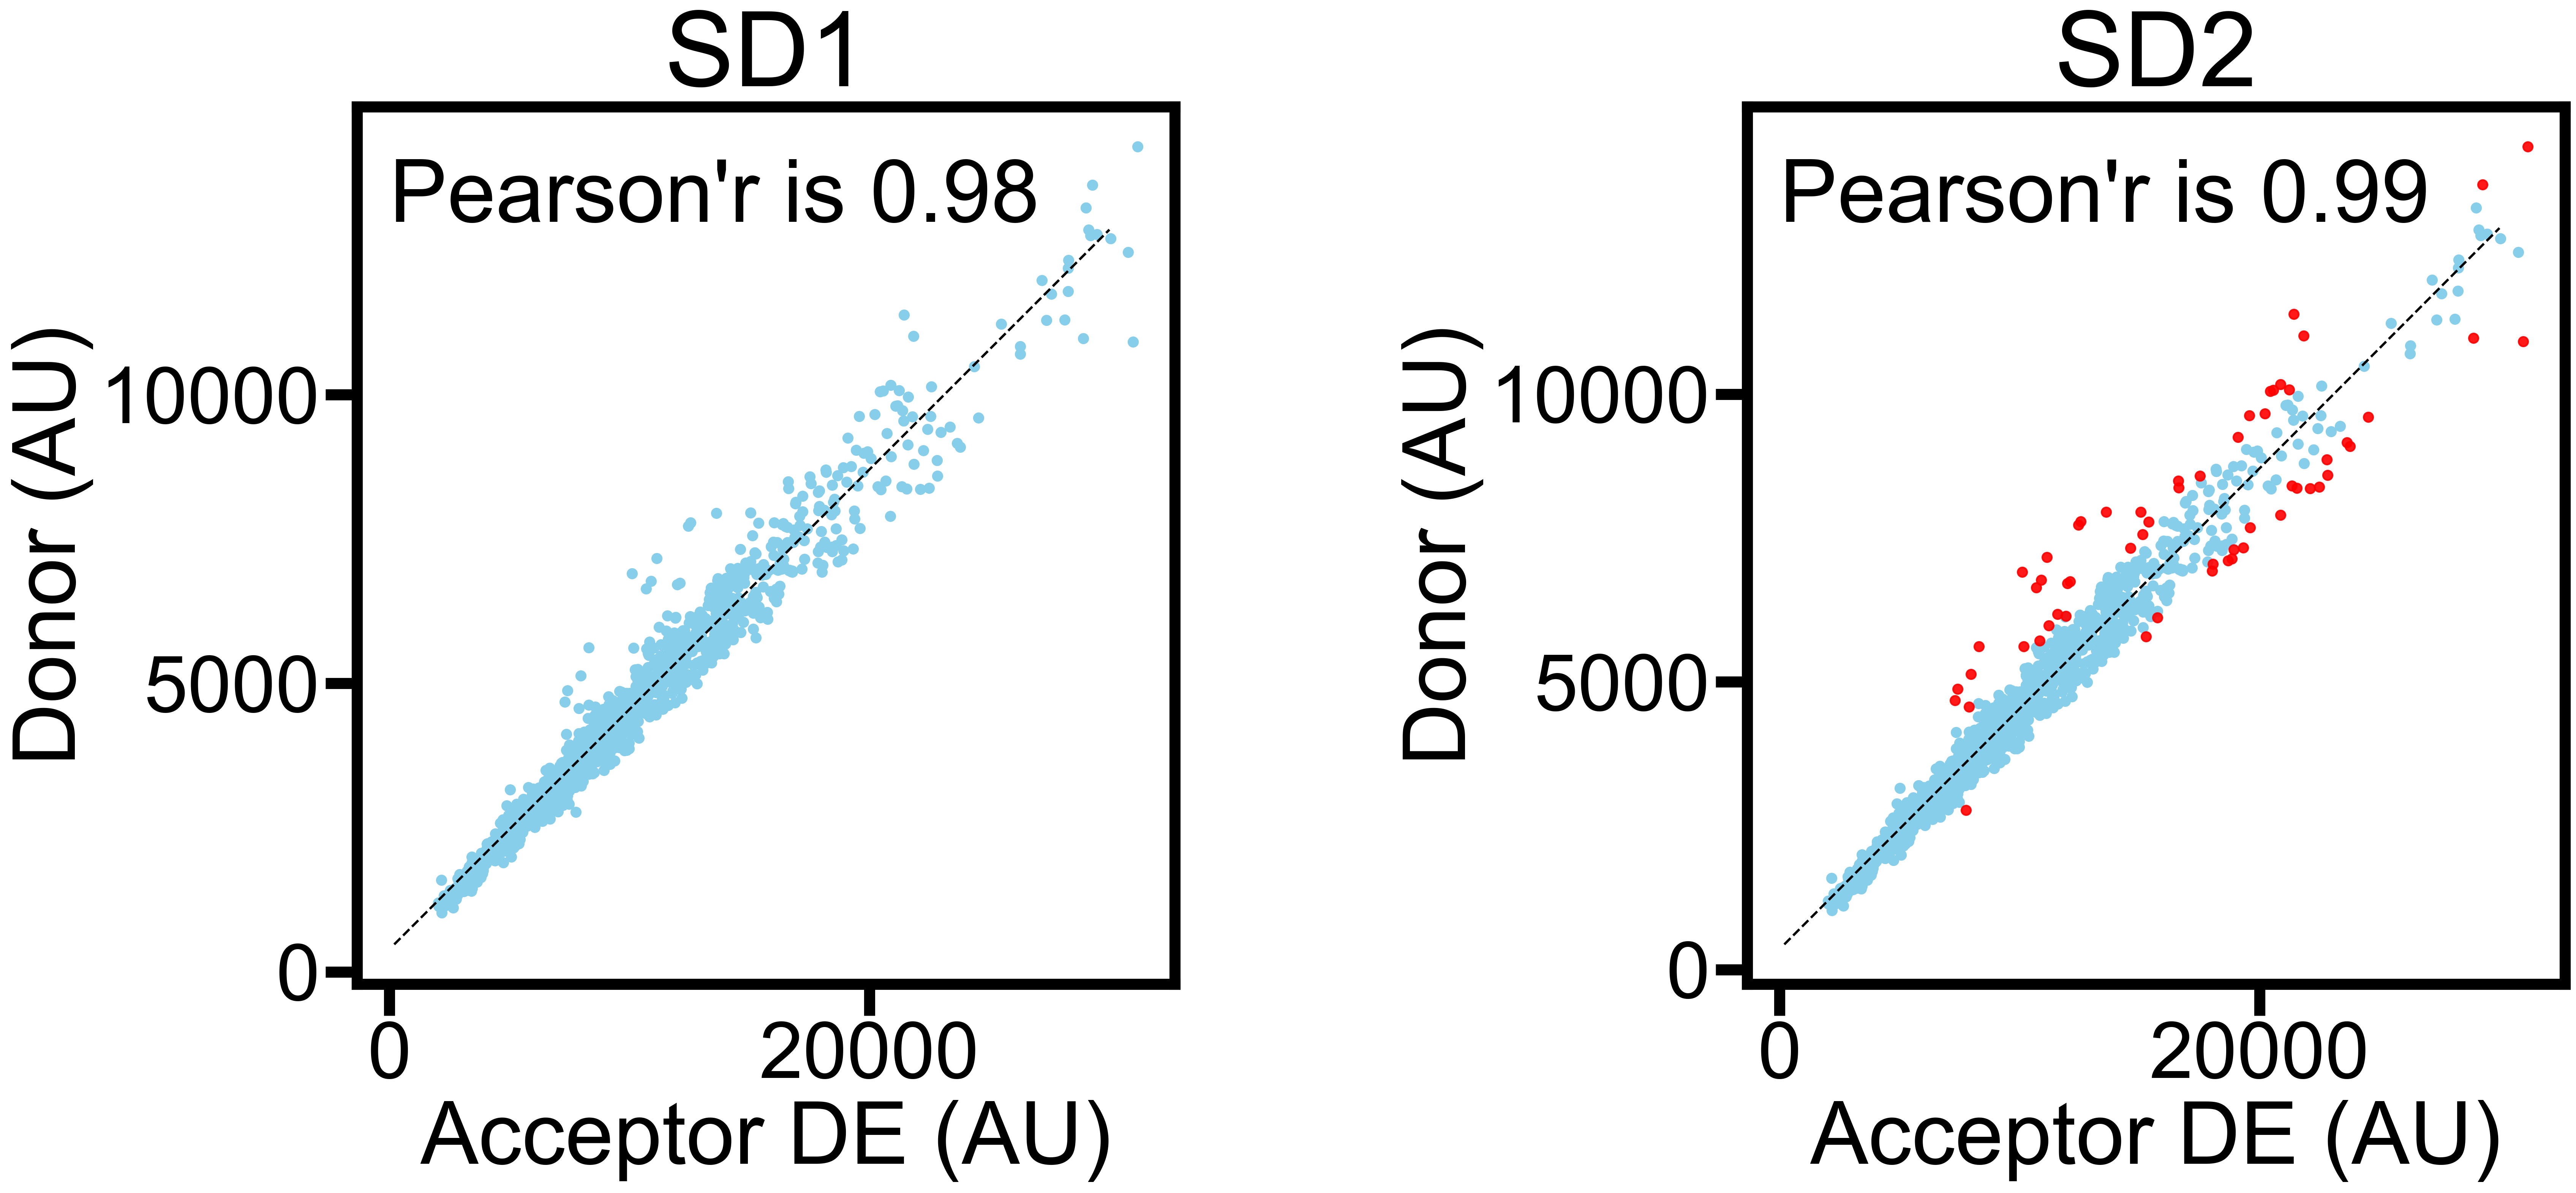

In [119]:
#highlighting a single tile, population, and timepoint for prior cleanup

from scipy.stats import linregress

fig, ax = plt.subplots(1, 2, figsize=(25, 10))
# adjust to see different population filters

#1-12 string
tile = "4"

#0-8 int
timepoint = 4

#"Growth", "nonifected", "infected"
population = "Growth"

#selection
show_case = recom_df.loc[(recom_df["construct"] ==tile) & (recom_df["timepoint"] ==timepoint) & (recom_df["experimentparameter"] ==population)]
show_case_clean = linear_clean.loc[(linear_clean["construct"] ==tile) & (linear_clean["timepoint"] ==timepoint) & (linear_clean["experimentparameter"] ==population)]
show_case_removed = removed.loc[(removed["construct"] ==tile) & (removed["timepoint"] ==timepoint) & (removed["experimentparameter"] ==population)]

fig_1 = ax[0]
fig_2 = ax[1]

#SD1
res= linregress(show_case["directAcceptor_intensity_mean"], show_case["donor_intensity_mean"])

rvalue = round(res.rvalue, 2)
fig_1.text(0.1, 13000, s=f"Pearson'r is {rvalue}")

slope, inter = res.slope, res.intercept
x = np.linspace(200, 30000, 30)

fig_1.plot(x, slope*x+inter, 'k--')
fig_1.scatter(show_case["directAcceptor_intensity_mean"], show_case["donor_intensity_mean"], color='skyblue')

#SD2
res= linregress(show_case_clean["directAcceptor_intensity_mean"], show_case_clean["donor_intensity_mean"])
rvalue = round(res.rvalue, 2)
fig_2.text(0.1, 13000, s=f"Pearson'r is {rvalue}")
slope, inter = res.slope, res.intercept
x = np.linspace(200, 30000, 30)

fig_2.plot(x, slope*x+inter, 'k--', zorder=3)

fig_2.scatter(show_case_clean["directAcceptor_intensity_mean"], show_case_clean["donor_intensity_mean"], zorder=2, color='skyblue')
fig_2.scatter(show_case_removed["directAcceptor_intensity_mean"], show_case_removed["donor_intensity_mean"], zorder=2, color='r', alpha=0.9)

#labels
fig_1.set_xlabel("Acceptor DE (AU)")
fig_2.set_xlabel("Acceptor DE (AU)")

fig_1.set_ylabel("Donor (AU)")
fig_2.set_ylabel("Donor (AU)")

fig_1.set_title("SD1")
fig_2.set_title("SD2")
plt.subplots_adjust(wspace=0.7)

In [117]:
linear_clean.groupby(["construct", "date","timepoint","experimentparameter", "well"])["Efret"].count().to_csv(r"population_counts.csv")

In [ ]:
#Further clean up not shown here is wells with less than 20 cells are dropped, 
#Wells that fall outside of 1 standard deviation of the experimental trend are dropped as well (reduces major trend outliers). 
#     Above: This based on delta Efret, so that even if something shows a mjor trend in a delta, if all experiments are not showing it, then it is a false 
#     positive change and will be removed. This can happen to the changes in population numbers and how cell are shifting between infected and noninfected.
#delta Efret is calculated to the median of the well of the nontreated and growth population

In [90]:
"""Functions for clean up"""
def acceptor_correction(df: pd.DataFrame, fret_stat:str = 'mean', crossex_correction: float=0.15, bleedthrough_correction:float=0.48, mCh_subtract=0.173)-> pd.DataFrame:
    
    df['crossexcitation_correction'] = crossex_correction
    df['bleedthrough_correction'] = bleedthrough_correction
    if 'mCherry_intensity_' + fret_stat in df.columns:
        df['directAcceptor_intensity_'+fret_stat] = df['directAcceptor_intensity_'+fret_stat] - df['mCherry_intensity_'+fret_stat] * mCh_subtract
    
    df['acceptor_corrected_'+fret_stat] = df['acceptor_intensity_'+fret_stat] - df['donor_intensity_'+fret_stat]*bleedthrough_correction-df['directAcceptor_intensity_'+fret_stat] * crossex_correction
    return df

def calculate_efret(df: pd.DataFrame, stat: str='mean')->pd.DataFrame:
    df['Efret'] = df['acceptor_corrected_'+stat]/(df['donor_intensity_'+stat]+df['acceptor_corrected_'+stat])
    return df

def pixels_to_micron(df: pd.DataFrame, area_column: str='area', pixels_per_micron: float = 3.0769) -> pd.DataFrame:
    df= df.rename(columns={area_column: 'area_pixels'})
    df['area_micron'] = df['area_pixels']/pixels_per_micron
    return df


def area_cutoffs(df: pd.DataFrame, area = 'area_micron', lower_cutoff:float = 600.0, upper_cutoff: float=7000)-> pd.DataFrame:
    df = df.loc[(df[area] > lower_cutoff) & (df[area] < upper_cutoff)]
    df = df.reset_index(drop=True)
    return df


def remove_maximums(df: pd.DataFrame, channel: str, value_cutoff: float = 55000)-> pd.DataFrame:
    channel_cutoff = channel+'_intensity_max'
    df = df.loc[df[channel_cutoff] < value_cutoff]
    df = df.reset_index(drop=True)
    return df 


def calculate_time(df: pd.DataFrame, experiment: str): 
    experiment_timeframe ={
        'infection' : 4,
        'osmoticperturbation' : 0.1,
        'heatshock': 0.5,
        'blasticidin': 0.5,
    }
    
    timeframe = experiment_time[experiment]
    df['time'] = df['timepoint'].astype(int) * timeframe
    return df


def remove_minimums(df: pd.DataFrame, channel: str, value_cutoff = 400)-> pd.DataFrame:
    channel_cutoff = channel+'_intensity_min'
    df = df.loc[df[channel_cutoff] > value_cutoff]
    df = df.reset_index(drop=True)
    return df


def directacceptor_mean_cutoffs(df: pd.DataFrame, lower_cutoff: float = 1000, upper_cutoff=40000) -> pd.DataFrame:
    df = df.loc[(df['directAcceptor_intensity_mean']> lower_cutoff) & (df['directAcceptor_intensity_mean'] < upper_cutoff)]
    return df


def donor_mean_cutoffs(df: pd.DataFrame, lower_cutoff: float = 600, upper_cutoff=20000) -> pd.DataFrame:
    df = df.loc[(df['donor_intensity_mean']> lower_cutoff) & (df['donor_intensity_mean'] < upper_cutoff)]
    return df

def infection_parameters(df: pd.DataFrame, group_values=['construct', 'timepoint', 'date', 'well'], lower_cutoff=0.15, upper_cutoff = 0.85) -> pd.DataFrame:
    df = df.copy()
    df['experimentparameter'] = 'mixed_population'
    
    tmp_df_holder = pd.DataFrame()

    for _, group in df.groupby(group_values):
        lower_threshold = group['mCherry_intensity_mean'].quantile(lower_cutoff)
        upper_threshold = group['mCherry_intensity_mean'].quantile(upper_cutoff)

        group = group.copy()
        group.loc[group['mCherry_intensity_mean'] <= lower_threshold, 'experimentparameter'] = 'noninfected'
        group.loc[group['mCherry_intensity_mean'] >= upper_threshold, 'experimentparameter'] = 'infected'

        tmp_df_holder = pd.concat([tmp_df_holder, group], ignore_index=True)

    return tmp_df_holder


def infection_cutoffs(df: pd.DataFrame, lower_cutoff=3000, upper_cutoff = 10000) -> pd.DataFrame:
    df = df.copy()

    noninfected =df.loc[df['mCherry_intensity_mean'] < lower_cutoff]
    mixed = df.loc[(df['mCherry_intensity_mean'] >= lower_cutoff) & (df['mCherry_intensity_mean'] <= upper_cutoff)]
    infected = df.loc[df['mCherry_intensity_mean'] > upper_cutoff]

    noninfected.loc[:, 'experimentparameter'] = 'noninfected'
    mixed.loc[:, 'experimentparameter'] = 'mixed_population'
    infected.loc[:, 'experimentparameter'] = 'infected'

    return pd.concat([noninfected, mixed, infected])

def set_categorical_order(df: pd.DataFrame, column_name: str, category_order: list[str]) -> pd.DataFrame:
    df = df.copy()  # Ensure we don't modify the original DataFrame in-place

    if column_name not in df.columns:
        raise ValueError(f"Column '{column_name}' not found in DataFrame")
    
    # Ensure existing values in the column are not lost
    existing_values = df[column_name].dropna().unique()
    
    # Combine user-defined order with existing unique values while preserving order
    complete_order = list(dict.fromkeys(category_order + list(existing_values)))  

    # Apply the categorical dtype
    cat_type = CategoricalDtype(categories=complete_order, ordered=True)
    df[column_name] = df[column_name].astype(cat_type)

    return df  # Return modified DataFrame without affecting other columns

def sort_values(df: pd.DataFrame, sort_dict: dict[str, List[str]])-> pd.DataFrame:
    tmp_df = df.copy()
    for index, sorter_values in sort_dict.items():
        tmp_df = set_categorical_order(tmp_df, index, sorter_values)
    return tmp_df

def remove_outliers(df, group_values, check_column='Efret', sub_groupers= ['date', 'well'], observed=False, as_index=False, std_dev = 2.8):
    """
    Remove outliers from a DataFrame based on median values outside the interquartile range.
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input DataFrame to process
    group_values : list or str
        Column(s) to group by for outlier detection
    check_column : str
        Column to check for outliers
    observed : bool, optional (default=True)
        Whether to use only observed values in groupby
    as_index : bool, optional (default=False)
        Whether to return groupby result as index
    
    Returns:
    --------
    pandas.DataFrame
        DataFrame with outliers removed
    """
    filtered_dfs = []

    # Loop through each group defined by group_values
    for name, group in df.groupby(group_values, observed=True, as_index=False):
        # Compute median 'Efret' per 'date' and 'well'
        median_df = group.groupby(sub_groupers, as_index=False)[check_column].median().dropna()
        
        # Calculate the z-score of the median values
        median_df['zscore'] = zscore(median_df[check_column])
        # Compute absolute zscore and flag groups where abs(zscore) > 2
        median_df['abs_zscore'] = median_df['zscore'].abs()
        median_df['outlier'] = median_df['abs_zscore'] > std_dev
      
        new_groupers = sub_groupers + ['abs_zscore', 'outlier']
        # Merge the outlier flag back to the original group on 'date' and 'well'
        group = group.merge(median_df[new_groupers], on=['date', 'well'], how='left')
        
            
        # Optionally, if you want to drop the groups flagged as outliers
        group_filtered = group[group['outlier'] == False]
        
        
        filtered_dfs.append(group_filtered)
        
    #display(abs(zscore(median_efret)) > 2)
        
        
    filtered_df = pd.concat(filtered_dfs, ignore_index=True)
    filtered_df = filtered_df.reset_index(drop=True)
    return filtered_df


def get_stats(
        df: pd.DataFrame,
        group_values: list,
        stats: tuple =('mean', 'median', 'min', 'max', 'std', 'count', 'var', 'list'),
        stat_column: str='Efret',
        observed:bool =True,
        as_index: bool=False,
        append_all_values:bool =True   
) -> pd.DataFrame():
    """
    Compute descriptive statistics on *stat_column* after grouping by *group_values*.

    Returns one column per requested statistic, named "<stat_column>_<stat>".

    Parameters
    ----------
    df : pd.DataFrame
    group_values : list[str]
        Column names to group by.
    stats : iterable[str]
        Any subset of {'mean','median','min','max','std','count','var','list'}.
    stat_column : str
        Column on which to compute the stats.
    observed, as_index : passed straight to DataFrame.groupby.
    append_all_values : bool
        If True, always add the `<stat_column>_list` column (even if
        'list' is not in *stats*).
    """
    stats = list(stats)  # ensure it is iterable

    # One-shot aggregation; pandas will return a DataFrame
    grouped = df.groupby(group_values, observed=observed, as_index=as_index)[stat_column]
    stat_funcs = [list if s == 'list' else s for s in stats]
    agg_df = grouped.agg(stat_funcs)
    # Rename columns (resulting column names from agg will be tuples if multiple functions)
    
    new_columns = {stat: stat_column+'_'+stat for stat in stats}
    
    agg_df = agg_df.rename(columns = new_columns)

    # Add back grouping columns explicitly if as_index=False (to ensure full mergeability)
    if not as_index:
        group_keys_df = df[group_values].drop_duplicates()
        result_df = pd.merge(group_keys_df, agg_df, left_on=group_values, right_on=group_values)
    else:
        result_df = agg_df

    return result_df
    
def delta_time(df, delta_column='Efret_median', comparison_column = 'Efret_median', group_values=['construct', 'experiment'], comparison: int = 1):
    df_copy = df.copy()

    if df_copy[delta_column].dtype == list:
        
        df_copy[delta_column] = df_copy[delta_column].apply(np.array)
        df_copy['delta_'+delta_column] = df_copy[delta_column] - df_copy.groupby(group_values, observed=False)[comparison_column].transform(lambda x: x.iloc[comparison])
    
    else:    
    
        df_copy['delta_'+delta_column] = df_copy[delta_column] - df_copy.groupby(group_values, observed=False)[delta_column].transform(lambda x: x.iloc[comparison])
        df_copy['delta_'+delta_column] = df_copy['delta_'+delta_column].fillna(0)

    return df_copy

def delta_list_median(df, delta_df, delta_column, comparison_column = 'Efret_median', group_values=['construct', 'experiment'], comparison: int =1):
    df_copy = df.copy()
    df_copy[delta_column] = df_copy[delta_column].apply(np.array)

    # Use nth(1) safely
    delta_medians = (
        delta_df.groupby(group_values, observed=False)[comparison_column]
        .apply(lambda x: x.iloc[comparison] if len(x) > 1 else np.nan)
        .reset_index()
    )
    delta_medians.rename(columns={comparison_column: 'Efret_median_delta'}, inplace=True)


    # Merge the median values onto df_copy based on group_values
    df_copy = df_copy.merge(delta_medians, on=group_values, how='left')
          
    # Subtract median from each element of the list column
    df_copy['delta_' + delta_column] = df_copy.apply(
        lambda row: row[delta_column] - row['Efret_median_delta'] 
        if np.isfinite(row['Efret_median_delta']) else np.nan, 
        axis=1
    )

    # Drop the extra merged column if not needed
    df_copy.drop(columns=['Efret_median_delta'], inplace=True)
    
    return df_copy

def remove_controls(df, control_1: str = 'mTQ2', control_2: str='mNG'):
    return df.loc[(df['construct']!= control_1) & (df['construct']!=control_2)]

def drop_counts(df, count_column = 'Efret_count', count=20):
    df = df.loc[df[count_column] > count]
    return df.reset_index(drop=True)

def get_population_significance(df, group_values, sign_column='Efret_median', observed=False,
                                 as_index=False, equal_var=True, nan_policy='propagate',
                                 comparison_value='Growth', comparison_column='experimentparameter'):
    
    groupby_df = df.groupby(group_values, observed=observed, as_index=as_index)
    sign_df = pd.DataFrame()
    comparison_population = None  # Store this globally so other groups can compare to it

    for group_key, group_data in groupby_df:
        # Convert group_key to dict using group_values
        group_dict = dict(zip(group_values, group_key if isinstance(group_key, tuple) else (group_key,)))

        # Extract comparison value
        current_comp_val = group_data[comparison_column].unique()[0]

        # If this group is the comparison group
        if current_comp_val == comparison_value:
            comparison_population = group_data[sign_column].values
            ttest, pvalue, star = 'NaN', 'NaN', 'ns'
        else:
            if comparison_population is None:
                raise ValueError(f"Comparison population for '{comparison_value}' not found before other group.")
            variable_population = group_data[sign_column].values
            ttest, pvalue = stats.ttest_ind(comparison_population, variable_population,
                                            nan_policy=nan_policy)
            star = set_pvalue(pvalue)

        # Build result dictionary
        result = {k: group_dict[k] for k in group_values}
        result.update({
            comparison_column: current_comp_val,
            'ttest': ttest,
            'pvalue': pvalue,
            'star_value': star
        })

        # Append to result dataframe
        sign_df = pd.concat([sign_df, pd.DataFrame([result])], ignore_index=True)

    return sign_df

def filter_linear(group, threshold=2):
    x = group["directAcceptor_intensity_mean"].values
    y = group["donor_intensity_mean"].values
    
    # Fit linear regression (degree 1 polynomial)
    slope, intercept = np.polyfit(x, y, 1)
    
    # Predicted values
    y_pred = slope * x + intercept
    
    # Residuals
    residuals = y - y_pred
    
    # Standardized residuals
    std_resid = residuals / np.std(residuals)
    
    # Keep rows within threshold
    df_keep = group[np.abs(std_resid) < threshold]
    
    return df_keep 
